# Emotional vs neutral prompts: same node, same day

**Question:** Do emotional prompts (**E**) produce more CPU throttling than neutral prompts (**N**) on the 70B model?

**Why matching:** Throttling varies a lot between machines and between days. To remove that, we only compare E with N runs made **on the same node on the same date**. Within each node/date, every E run is compared with every N run.

**What we measure** (PTE = processor throttle events, from `core_power.throttle`):
- **PTE mean rate** — throttle events per second.
- **PTE / cycles** — throttle events per CPU cycle. This is less sensitive to how long a run lasted.

Positive numbers mean **E > N**. Inputs and earlier notebooks are read-only; all outputs go to `OUT`.

**Steps**
1. Find the node/date pairs that have both E and N runs.
2. Compare every E run with every N run in each node/date.
3. Estimate the overall difference and its uncertainty.
4. Check whether the direction holds across dates and nodes.
5. Check whether a single date or node drives the result.
6. Check the model's assumptions.
7. Conclusion. (Method details are in the appendix at the end.)

In [1]:
from pathlib import Path
import sys, json, hashlib, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/features/recomputed/fulltrace").is_dir())
sys.path.insert(0, str(ROOT / "analysis/lib"))
import fulltrace_matched
importlib.reload(fulltrace_matched)  # pick up edits without restarting the kernel
from fulltrace_matched import prepare, analyze, block_summary, display_effect, SPECS as ALL_SPECS

SELECTED_FEATURES = {"core_power.throttle__mean_rate",
                     "core_power.throttle__per_cycle"}
RENAME = {"core_power.throttle__mean_rate": "PTE mean rate"}
SPECS = [(feature, RENAME.get(feature, label), scale, unit)
         for feature, label, scale, unit in ALL_SPECS if feature in SELECTED_FEATURES]

TIMEZONE = "America/Chicago"
TEST_BOOTSTRAPS = 19999
INTERVAL_BOOTSTRAPS = 1999
SEED = 42
WORKERS = 4  # Use 1 for a single process.
OUT = ROOT / "results/fulltrace_matched_EN_2026-10-24_two_features"
OUT.mkdir(parents=True, exist_ok=True)
E_COLOR, N_COLOR = "#C44E52", "#4477AA"
FEATURES = [s[0] for s in SPECS]
LABELS = {s[0]: s[1] for s in SPECS}
UNITS = {s[0]: s[3] for s in SPECS}
pd.set_option("display.max_rows", 100)

def save_figure(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("Each row below will be a matched comparison, not an individual timestamp.")

Each row below will be a matched comparison, not an individual timestamp.


## 1. Find matched node/date pairs

- **Included:** successful 70B E and N runs that have recomputed feature files. Joy, mechanical and aggregate files are excluded.
- **Date:** the run's start date in Chicago time. A run that crosses midnight counts on the day it started.
- **Node:** taken from the folder label. We assume the same label means the same physical machine.
- **Unequal runs:** node 187 on 2026-10-25 has only one neutral run (the second was not collected). It is kept: its two E runs are each compared with that one N run.
- A node/date with only E or only N runs can't be compared, so it is listed and dropped.

The heatmap shows which node/date pairs we have, and how many runs each contains.

,count
quantity,
Recordings,88
Matched node/date groups,27
Nodes,21
Dates,8
One E + one N,10
Two E + two N,16
Other run counts,1
E×N cross pairs per measure,76
Cross-midnight recordings,5


condition,emotional,neutral
batch,,
batch_001_en,19,20
batch_003_enj,10,10
batch_004_enm,5,5
batch_005_nem,10,9


Excluded other conditions/models: 45; unmatched groups: 1


condition,node,day,emotional,neutral
0,232,2026-05-12,0,1


,day,node,batch,n_E,n_N
0,2026-05-04,244,batch_001_en,2,2
1,2026-05-04,249,batch_001_en,1,1
2,2026-05-06,230,batch_001_en,2,2
3,2026-05-07,226,batch_001_en,1,1
4,2026-05-10,222,batch_001_en,2,2
5,2026-05-10,224,batch_001_en,2,2
6,2026-05-10,229,batch_001_en,2,2
7,2026-05-10,246,batch_001_en,2,2
8,2026-05-10,252,batch_001_en,2,2
9,2026-05-12,231,batch_001_en,1,1


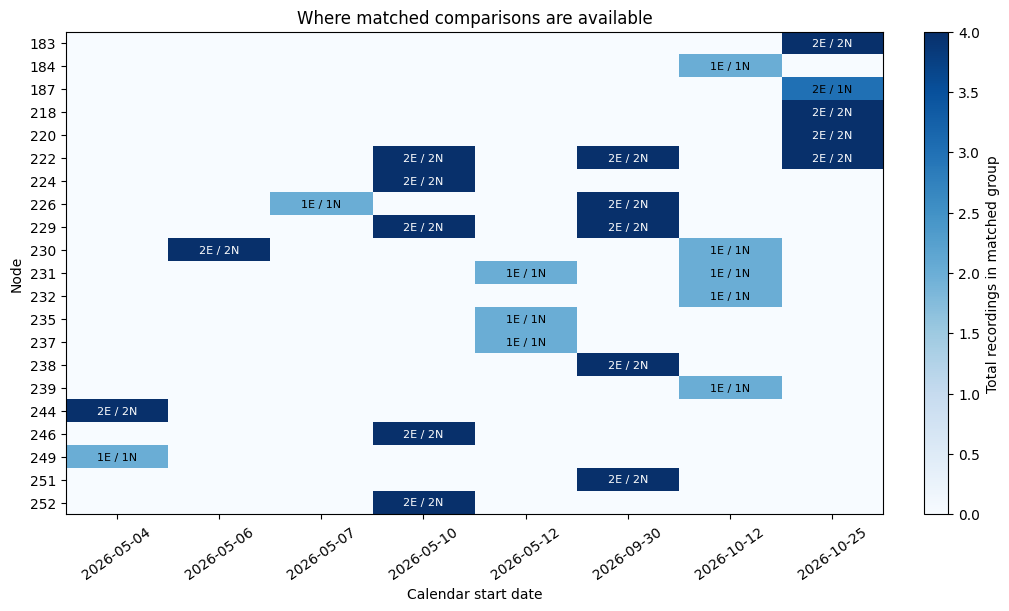

In [2]:
traces, blocks, contrasts, sources, excluded, unmatched = prepare(ROOT, TIMEZONE, features=FEATURES)
contrasts["label"] = contrasts.feature.map(LABELS)
block_contrasts = block_summary(contrasts)
traces = traces.loc[:, [column for column in traces if "__" not in column or column in FEATURES]]
coverage = pd.DataFrame({"quantity": ["Recordings", "Matched node/date groups", "Nodes", "Dates",
                                   "One E + one N", "Two E + two N", "Other run counts",
                                   "E×N cross pairs per measure", "Cross-midnight recordings"],
                         "count": [len(traces), len(blocks), blocks.node.nunique(), blocks.day.nunique(),
                                   int(((blocks.n_E == 1) & (blocks.n_N == 1)).sum()),
                                   int(((blocks.n_E == 2) & (blocks.n_N == 2)).sum()),
                                   int((blocks.n_E != blocks.n_N).sum()),
                                   int((blocks.n_E * blocks.n_N).sum()),
                                   int(traces.crosses_midnight.sum())]})
display(coverage.set_index("quantity"))
display(pd.crosstab(traces.batch, traces.condition))
print(f"Excluded other conditions/models: {len(excluded)}; unmatched groups: {len(unmatched)}")
if len(unmatched): display(unmatched)
display(blocks[["day", "node", "batch", "n_E", "n_N"]])
for name, table in [("input_recordings", traces), ("matched_groups", blocks),
                    ("matched_contrasts", contrasts), ("block_summaries", block_contrasts),
                    ("input_checksums", sources),
                    ("excluded_recordings", excluded), ("unmatched_groups", unmatched)]:
    table.to_csv(OUT / f"{name}.csv", index=False)

nodes = sorted(blocks.node.unique(), key=int)
dates = sorted(blocks.day.unique())
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
values = np.zeros((len(nodes), len(dates)))
for row in blocks.itertuples(index=False):
    i, j = nodes.index(row.node), dates.index(row.day)
    values[i, j] = row.n_E + row.n_N
im = ax.imshow(values, cmap="Blues", vmin=0, vmax=max(4, values.max()), aspect="auto")
for row in blocks.itertuples(index=False):
    ax.text(dates.index(row.day), nodes.index(row.node), f"{row.n_E}E / {row.n_N}N",
            ha="center", va="center", fontsize=8,
            color="white" if row.n_E + row.n_N >= 4 else "black")
ax.set(xticks=range(len(dates)), xticklabels=dates, yticks=range(len(nodes)), yticklabels=nodes,
       xlabel="Calendar start date", ylabel="Node", title="Where matched comparisons are available")
ax.tick_params(axis="x", rotation=35)
fig.colorbar(im, ax=ax, label="Total recordings in matched group")
save_figure(fig, "coverage")

## 2. Compare every E run with every N run

Within each node/date, every E run is compared with every N run. With 2 runs per condition that gives four differences, E1−N1, E1−N2, E2−N1 and E2−N2; with 2 E and 1 N it gives two:

> difference = E run / N run − 1, shown as a percentage

(The model works with log(E / N) and converts back to % for display.)

These differences are **not independent**: they reuse the same runs, and in a 2+2 node/date the fourth one follows exactly from the other three. Section 3 explains how the model handles this.

**Figures**
- **Left plot:** each line joins the N run and the E run of one cross pair.
- **Right plot:** every cross pair as a small dot (red = E higher, blue = N higher). The black diamond is the node/date's average.

**Worked example from your data: 2026-05-04 / 244**

,E_run,N_run,E_value,N_value,effect,unit
label,,,,,,
PTE mean rate,244_1e,244_1n,1.1853e+09,1.0792e+09,9.8298,% vs neutral
PTE mean rate,244_1e,244_2n,1.1853e+09,1.0887e+09,8.8716,% vs neutral
PTE mean rate,244_2e,244_1n,1.1281e+09,1.0792e+09,4.5269,% vs neutral
PTE mean rate,244_2e,244_2n,1.1281e+09,1.0887e+09,3.615,% vs neutral
PTE / cycles,244_1e,244_1n,0.0092432,0.0083332,10.921,% vs neutral
PTE / cycles,244_1e,244_2n,0.0092432,0.008383,10.262,% vs neutral
PTE / cycles,244_2e,244_1n,0.0087166,0.0083332,4.6005,% vs neutral
PTE / cycles,244_2e,244_2n,0.0087166,0.008383,3.9794,% vs neutral


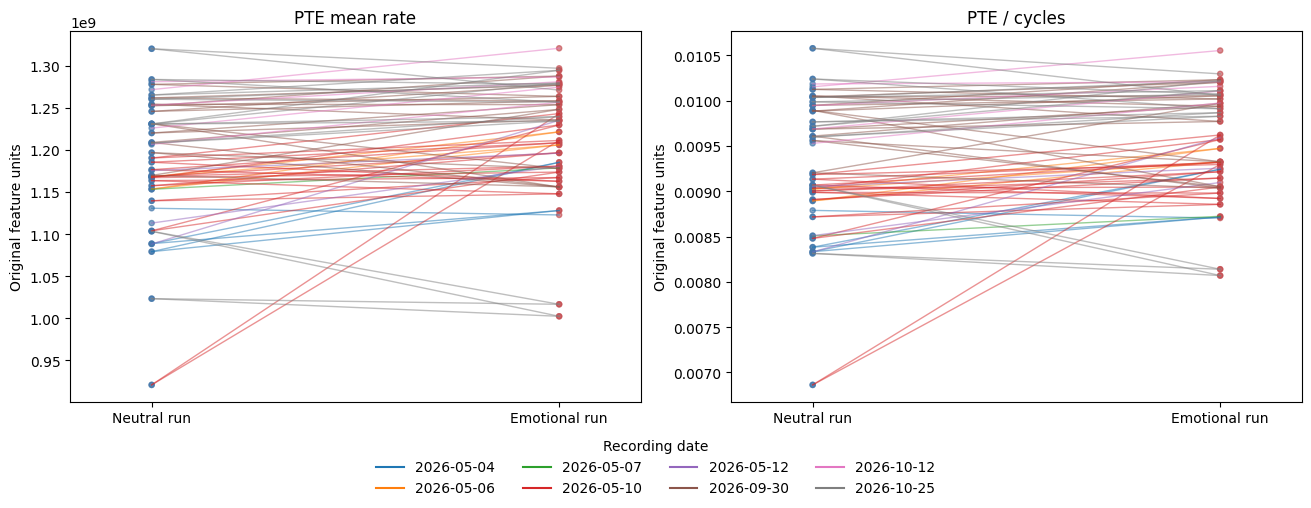

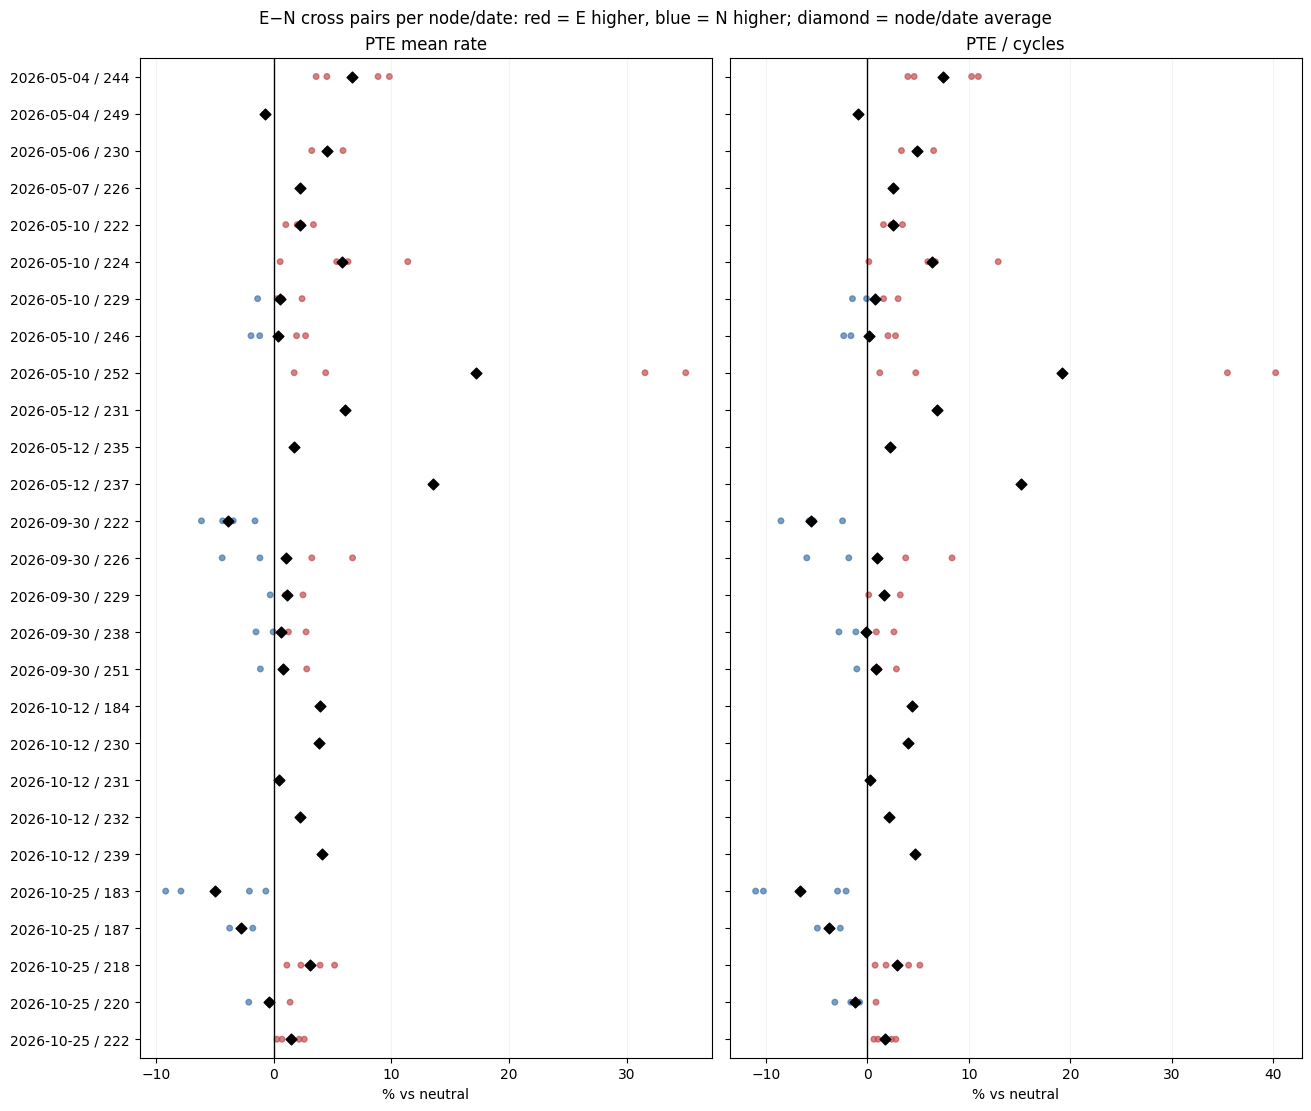

In [3]:
example = contrasts.loc[contrasts.block == blocks.block.iloc[0],
    ["label", "E_run", "N_run", "E_value", "N_value", "effect", "unit"]]
display(Markdown(f"**Worked example from your data: {blocks.block.iloc[0]}**"))
with pd.option_context("display.float_format", "{:.5g}".format):
    display(example.set_index("label"))

date_colors = dict(zip(dates, plt.get_cmap("tab10").colors[:len(dates)]))
fig, axes = plt.subplots(1, len(SPECS), figsize=(13, 5), layout="constrained")
for ax, (feature, label, scale, unit) in zip(axes.flat, SPECS):
    sub = contrasts.loc[contrasts.feature == feature]
    for row in sub.itertuples(index=False):
        ax.plot([0, 1], [row.N_value, row.E_value], color=date_colors[row.day], alpha=.5, linewidth=1)
        ax.scatter([0, 1], [row.N_value, row.E_value], color=[N_COLOR, E_COLOR], s=14, alpha=.65)
    ax.set(xticks=[0, 1], xticklabels=["Neutral run", "Emotional run"], title=label,
           ylabel="Original feature units", xlim=(-.2, 1.2))
    ax.ticklabel_format(axis="y", style="sci", scilimits=(-3, 4))
fig.legend([plt.Line2D([0], [0], color=date_colors[d]) for d in dates], dates,
                     title="Recording date", loc="outside lower center", ncol=4, frameon=False)
save_figure(fig, "paired_runs")

fig, axes = plt.subplots(1, len(SPECS), figsize=(13, 11), sharey=True, layout="constrained")
for ax, (feature, label, scale, unit) in zip(axes, SPECS):
    sub = contrasts.loc[contrasts.feature == feature]
    means = block_contrasts.loc[block_contrasts.feature == feature].set_index("block")
    for i, block in enumerate(blocks.block):
        pairs = sub.loc[sub.block == block, "effect"]
        ax.scatter(pairs, np.full(len(pairs), i), s=16, alpha=.7,
                   color=[E_COLOR if v > 0 else N_COLOR for v in pairs])
        ax.scatter(means.loc[block, "effect"], i, marker="D", s=30, color="black", zorder=3)
    ax.axvline(0, color="black", linewidth=1)
    ax.set(title=label, xlabel=unit, yticks=range(len(blocks)), yticklabels=blocks.block)
    ax.set_ylim(len(blocks)-.5, -.5)
    ax.grid(axis="x", alpha=.15)
fig.suptitle("E−N cross pairs per node/date: red = E higher, blue = N higher; diamond = node/date average", fontsize=12)
save_figure(fig, "matched_differences")

## 3. The overall E−N difference and its uncertainty

We combine the matched differences into one overall estimate. Two issues need care:

- **Cross pairs share runs.** E1−N1 and E1−N2 both use E1, so if E1 happened to be high, both look high. Counting the four cross pairs of a node/date as four independent results would overstate the evidence. The model therefore links pairs that **share an E run or an N run**. It also adds a **node/date** term, because all pairs from one node on one day may sit higher or lower together.
- **Node/dates aren't fully independent either.** Node/dates on the same node, or on the same date, may resemble each other. The model allows for this with node and date terms, so a date with many node/dates isn't over-counted.
- **The effect may vary between pairs.** So we report two ranges:
  - **95% CI** — how precisely we know the *average* difference.
  - **New-group range** — where the difference for a *new* node on a *new* date would likely fall. This range is wider, and it can include zero even when the average is clearly positive.

**p-value:** tests whether the average difference is zero. It is corrected (Bonferroni: each p × 2) for testing two metrics.

**Caveat:** these two metrics were chosen *after* looking at the data, from five PTE metrics. Correcting only for two is therefore optimistic. To see what correcting over all five would do, multiply the smaller raw p-value by 5. Treat the results as **exploratory**.

Model and test details are in the appendix.

In [4]:
estimates, sensitivity, residuals, bootstrap_means = analyze(
    contrasts, test_repeats=TEST_BOOTSTRAPS, interval_repeats=INTERVAL_BOOTSTRAPS,
    seed=SEED, workers=WORKERS,
)
for name, table in [("overall_effects", estimates), ("leave_one_group_out", sensitivity),
                    ("model_residuals", residuals), ("bootstrap_means", bootstrap_means)]:
    table.to_csv(OUT / f"{name}.csv", index=False)
configuration = dict(timezone=TIMEZONE, date_rule="trace start date", seed=SEED,
                     test_bootstraps=TEST_BOOTSTRAPS, interval_bootstraps=INTERVAL_BOOTSTRAPS,
                     workers=WORKERS, features=FEATURES, n_traces=len(traces), n_groups=len(blocks),
                     correction="Bonferroni over two overall E-N tests", estimation="Gaussian ML",
                     pairing="every E run vs every N run within node/date; shared-run covariance",
                     n_cross_pairs=int((blocks.n_E * blocks.n_N).sum()),
                     interval="studentized parametric bootstrap; pointwise 95%",
                     prediction="approximate bootstrap mixture for new node and new date")
(OUT / "configuration.json").write_text(json.dumps(configuration, indent=2) + "\n")

report = pd.DataFrame({"Feature": estimates.label, "Units": estimates.unit,
    "Overall E−N": estimates.display_estimate,
    "95% CI lower": estimates.display_ci_low, "95% CI upper": estimates.display_ci_high,
    "New-group range lower": estimates.display_prediction_low,
    "New-group range upper": estimates.display_prediction_high,
    "Bonferroni p": estimates.p_bonferroni,
    "E > N node/dates": [f"{p}/{len(blocks)}" for p in estimates.n_positive],
    "E > N cross pairs": [f"{p}/{n}" for p, n in zip(estimates.n_pairs_positive, estimates.n_pairs)],
    "MC-sensitive": estimates.mc_sensitive})
display(report.round(4))
report.to_csv(OUT / "readable_summary.csv", index=False)
print("A confidence interval excluding zero and a Bonferroni test answer different questions: intervals are pointwise.")
if estimates.mc_sensitive.any():
    display(estimates.loc[estimates.mc_sensitive, ["label", "p_bonferroni", "p_bonferroni_mc_low", "p_bonferroni_mc_high"]])

Completed 1/2: PTE mean rate


Completed 2/2: PTE / cycles


,Feature,Units,Overall E−N,95% CI lower,95% CI upper,New-group range lower,New-group range upper,Bonferroni p,E > N node/dates,E > N cross pairs,MC-sensitive
0,PTE mean rate,% vs neutral,2.6359,0.3397,4.9648,-8.2194,14.6327,0.0586,22/27,53/76,False
1,PTE / cycles,% vs neutral,2.6579,-0.0519,5.3003,-9.6440,16.6000,0.1120,21/27,53/76,False


A confidence interval excluding zero and a Bonferroni test answer different questions: intervals are pointwise.


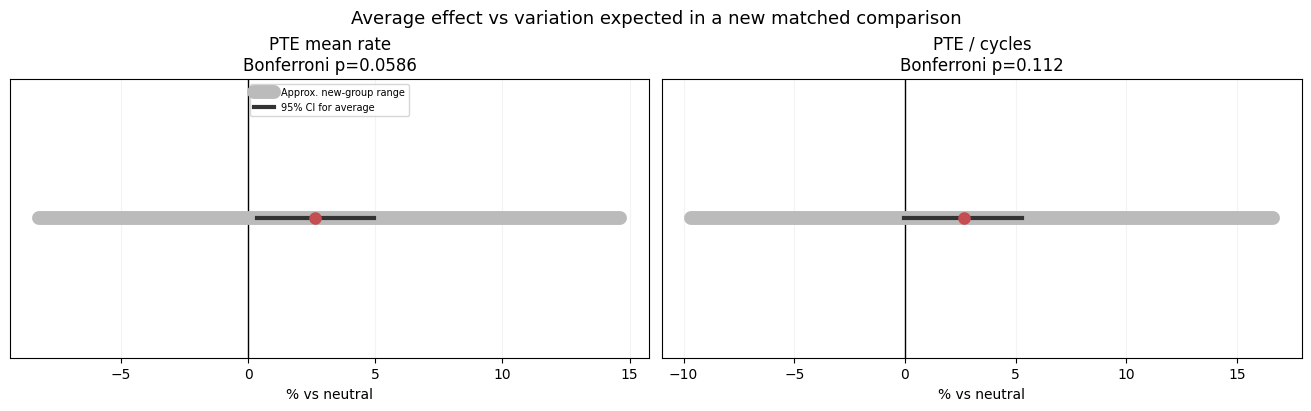

In [5]:
fig, axes = plt.subplots(1, len(SPECS), figsize=(13, 4), layout="constrained")
for ax, row in zip(axes, estimates.itertuples(index=False)):
    ax.axvline(0, color="black", linewidth=1)
    ax.plot([row.display_prediction_low, row.display_prediction_high], [0, 0],
            color="#BBBBBB", linewidth=10, solid_capstyle="round", label="Approx. new-group range")
    ax.plot([row.display_ci_low, row.display_ci_high], [0, 0], color="#333333", linewidth=3,
            label="95% CI for average")
    ax.scatter(row.display_estimate, 0, s=65, zorder=5,
               color=E_COLOR if row.display_estimate > 0 else N_COLOR)
    ax.set(title=f"{row.label}\nBonferroni p={row.p_bonferroni:.3g}", xlabel=row.unit, yticks=[], ylim=(-1, 1))
    ax.grid(axis="x", alpha=.15)
axes[0].legend(fontsize=7, loc="upper center")
fig.suptitle("Average effect vs variation expected in a new matched comparison", fontsize=13)
save_figure(fig, "overall_effects")

## 4. Does the direction hold across dates and nodes?

Gray dots are node/date averages (one per node/date). Each diamond summarizes all pairs on one date (top figure) or one node (bottom figure).

**What to look for:** most diamonds on the same side of zero. Several positive dots on a single date are still just one date, not independent confirmations.

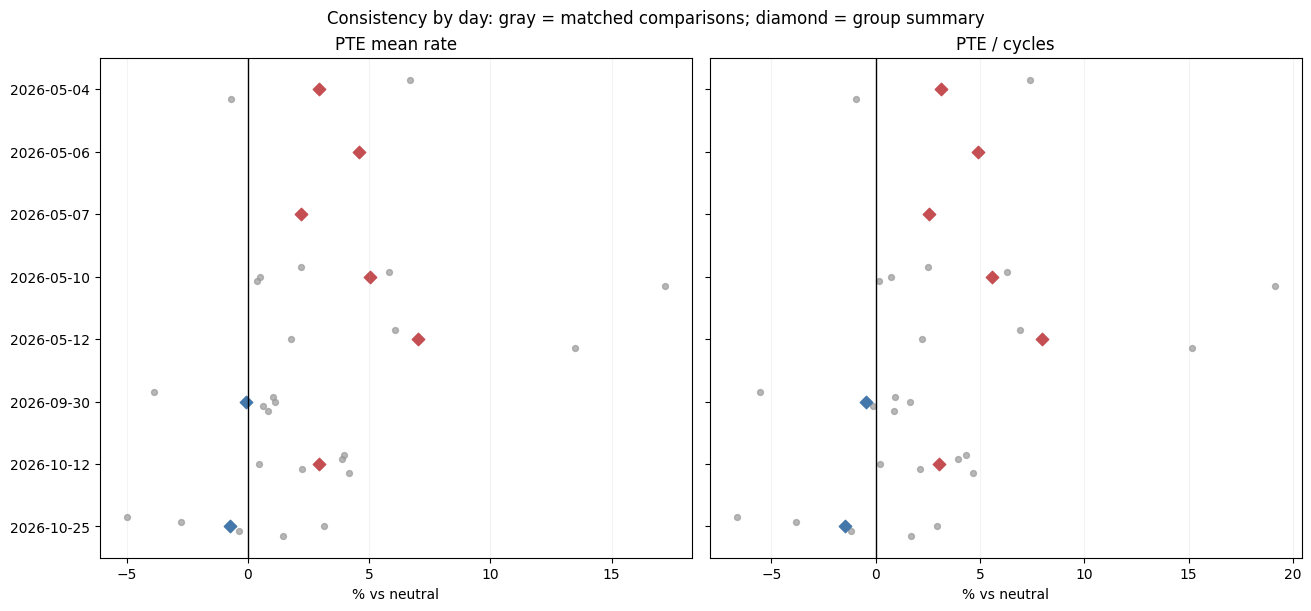

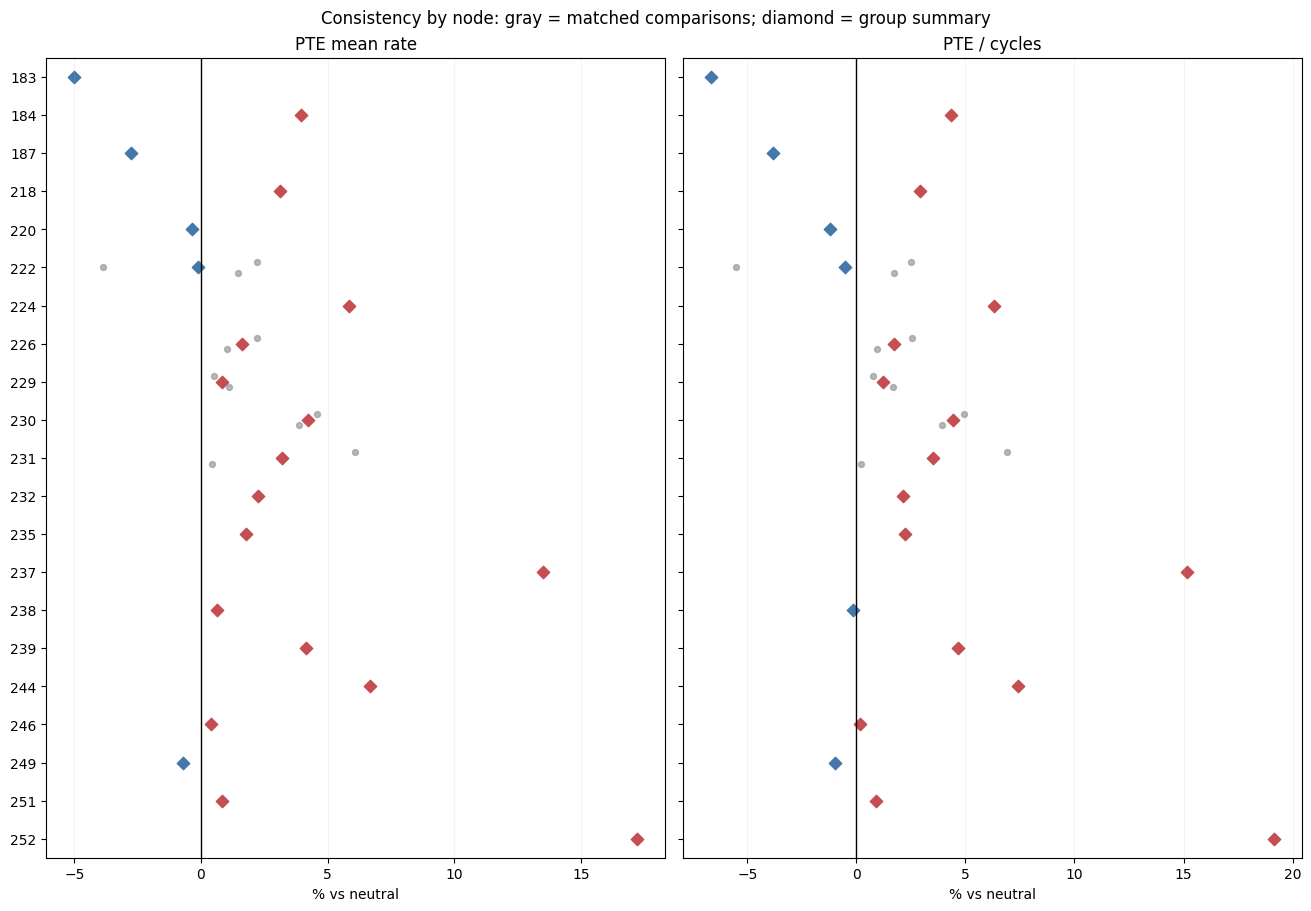

In [6]:
group_summaries = []
for grouping, height in [("day", 6), ("node", 9)]:
    groups = sorted(blocks[grouping].unique(), key=int if grouping == "node" else None)
    fig, axes = plt.subplots(1, len(SPECS), figsize=(13, height), sharey=True, layout="constrained")
    for ax, (feature, label, scale, unit) in zip(axes, SPECS):
        sub = block_contrasts.loc[block_contrasts.feature == feature]
        for i, group in enumerate(groups):
            values = sub.loc[sub[grouping] == group]
            summary = float(display_effect(values.contrast.mean(), scale))
            jitter = np.linspace(-.15, .15, len(values)) if len(values) > 1 else [0]
            ax.scatter(values.effect, i + np.asarray(jitter), s=18, color="#999999", alpha=.7)
            ax.scatter(summary, i, marker="D", s=40, color=E_COLOR if summary > 0 else N_COLOR)
            group_summaries.append(dict(grouping=grouping, group=group, feature=feature,
                                        n_blocks=len(values), mean_contrast=values.contrast.mean(),
                                        display_effect=summary,
                                        n_positive=int((values.contrast > 0).sum())))
        ax.axvline(0, color="black", linewidth=1)
        ax.set(title=label, xlabel=unit, yticks=range(len(groups)), yticklabels=groups,
               ylim=(len(groups)-.5, -.5))
        ax.grid(axis="x", alpha=.15)
    fig.suptitle(f"Consistency by {grouping}: gray = matched comparisons; diamond = group summary")
    save_figure(fig, f"consistency_by_{grouping}")
group_summaries = pd.DataFrame(group_summaries)
group_summaries.to_csv(OUT / "descriptive_group_summaries.csv", index=False)

## 5. Does one date or node drive the result?

Drop **one whole date** (purple) or **one whole node** (green), refit, and compare the estimate with the full-data value (dashed line).

**What to look for:** estimates that stay on the same side of zero with roughly the same size. This is a robustness check, not a new test. Each reduced dataset doesn't need to be significant by itself.

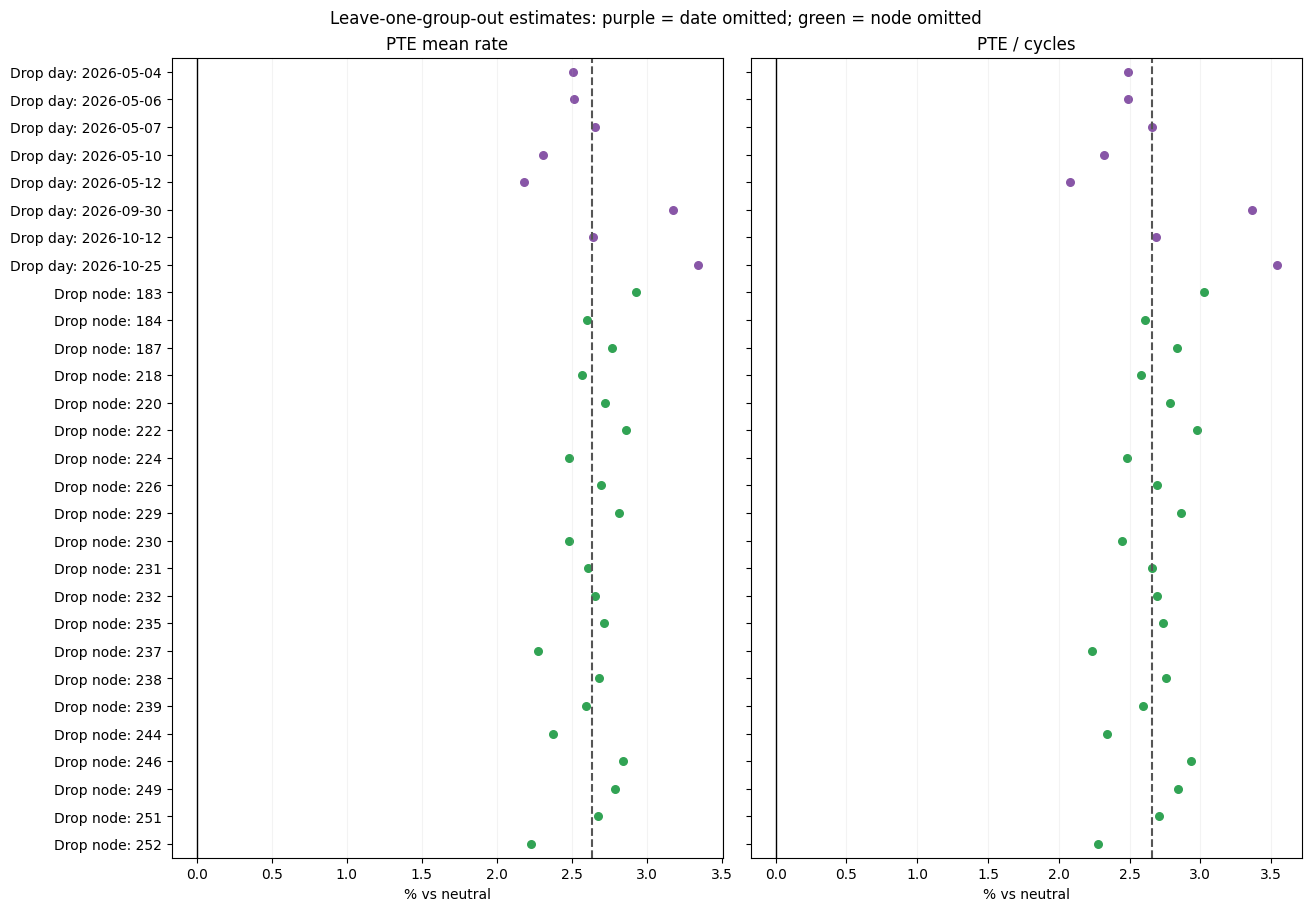

refits  same_direction  smallest_estimate  \
label         omitted_type                                              
PTE / cycles  day                8               8             2.0783   
              node              21              21             2.2366   
PTE mean rate day                8               8             2.1788   
              node              21              21             2.2306   

                            largest_estimate  
label         omitted_type                    
PTE / cycles  day                     3.5387  
              node                    3.0242  
PTE mean rate day                     3.3396  
              node                    2.9317

In [7]:
fig, axes = plt.subplots(1, len(SPECS), figsize=(13, 9), sharey=True, layout="constrained")
order = list(sensitivity.loc[sensitivity.feature == FEATURES[0], ["omitted_type", "omitted"]].itertuples(index=False, name=None))
ylabels = [f"Drop {kind}: {name}" for kind, name in order]
for ax, row in zip(axes, estimates.itertuples(index=False)):
    sub = sensitivity.loc[sensitivity.feature == row.feature].set_index(["omitted_type", "omitted"])
    for i, key in enumerate(order):
        ax.scatter(sub.loc[key, "display_estimate"], i,
                   color="#8856A7" if key[0] == "day" else "#31A354", s=30)
    ax.axvline(0, color="black", linewidth=1)
    ax.axvline(row.display_estimate, color="#555555", linestyle="--", label="Full-data estimate")
    ax.set(title=row.label, xlabel=row.unit, yticks=range(len(order)), yticklabels=ylabels,
           ylim=(len(order)-.5, -.5))
    ax.grid(axis="x", alpha=.15)
fig.suptitle("Leave-one-group-out estimates: purple = date omitted; green = node omitted")
save_figure(fig, "leave_one_group_out")

sensitivity_summary = sensitivity.groupby(["label", "omitted_type"]).agg(
    refits=("same_sign", "size"), same_direction=("same_sign", "sum"),
    smallest_estimate=("display_estimate", "min"), largest_estimate=("display_estimate", "max"))
display(sensitivity_summary.round(4))
sensitivity_summary.to_csv(OUT / "sensitivity_summary.csv")

## 6. Check the model's assumptions

- **Left:** how much of the variation in a single E−N cross pair comes from the node, the date, the node/date combination, or run-to-run noise (one run simply coming out higher or lower than another). A zero share is allowed. With this little data, the shares are rough.
- **Right:** a Q–Q plot. If the model's normality assumption holds, points lie near the dashed line. Points far from it are outliers that make the p-values less trustworthy.

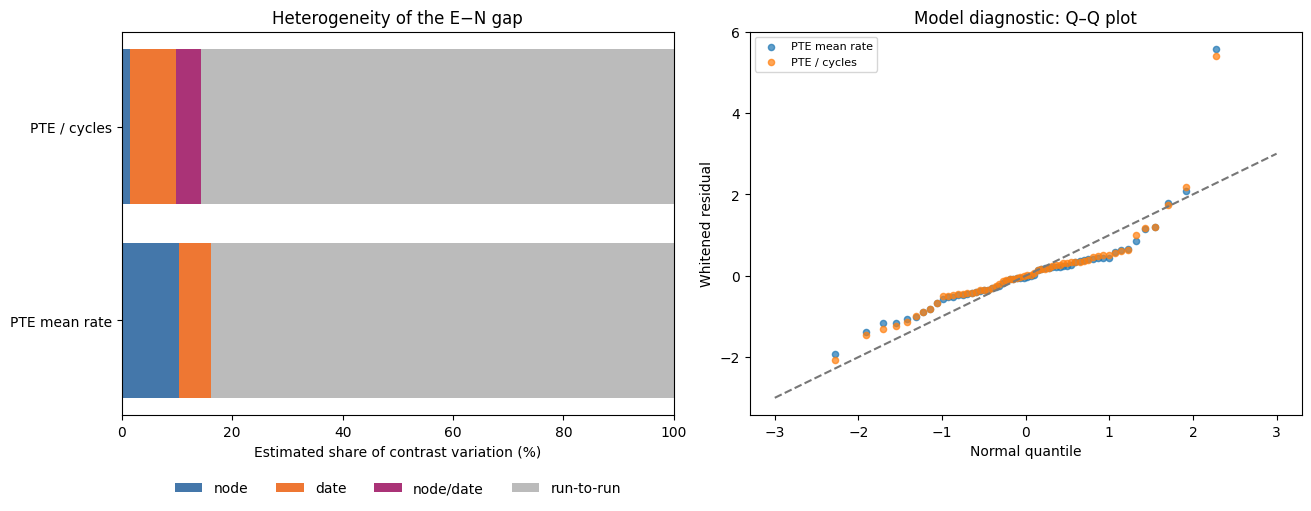

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
left = np.zeros(len(estimates))
for effect, name, color in [("node", "node", "#4477AA"), ("day", "date", "#EE7733"),
                            ("block", "node/date", "#AA3377"), ("residual", "run-to-run", "#BBBBBB")]:
    values = 100 * estimates[effect + "_fraction"].to_numpy()
    axes[0].barh(range(len(estimates)), values, left=left, color=color, label=name)
    left += values
axes[0].set(yticks=range(len(estimates)), yticklabels=estimates.label, xlim=(0, 100),
            xlabel="Estimated share of contrast variation (%)", title="Heterogeneity of the E−N gap")
axes[0].legend(loc="upper center", bbox_to_anchor=(.5, -.14), ncol=4, frameon=False)
for feature, label, scale, unit in SPECS:
    values = residuals.loc[residuals.feature == feature, "whitened_residual"]
    theoretical, ordered = stats.probplot(values, fit=False)
    axes[1].scatter(theoretical, ordered, s=20, label=label, alpha=.7)
axes[1].plot([-3, 3], [-3, 3], color="#777777", linestyle="--")
axes[1].set(xlabel="Normal quantile", ylabel="Whitened residual", title="Model diagnostic: Q–Q plot")
axes[1].legend(fontsize=8)
save_figure(fig, "model_diagnostics")

## 7. Conclusion

How to read each result below:

- **Is there an average difference?** Only if the corrected p < 0.05. Remember the selection caveat in section 3.
- **Is it consistent?** Check the per-pair plot, the date/node summaries, the drop-one checks, and whether the new-group range crosses zero.
- **Would it replicate?** Only fresh node/date data can really answer that.

**Limits:**
- Matching removes baseline differences between machines and days, not every possible confound. Examples are run order, setup, and the fact that dates and batches coincide.
- Only a few nodes appear on more than one date, so node and date effects are hard to separate.

In [9]:
for row in estimates.itertuples(index=False):
    loo = sensitivity.loc[sensitivity.feature == row.feature]
    verdict = "passes the two-metric correction" if row.supported else "does not pass the two-metric correction"
    prediction_note = "includes both directions" if row.prediction_crosses_zero else "keeps one direction under the model"
    display(Markdown(
        f"**{row.label}:** average E−N = **{row.display_estimate:+.3g} {row.unit}** "
        f"(pointwise 95% CI {row.display_ci_low:+.3g} to {row.display_ci_high:+.3g}); "
        f"Bonferroni p = **{row.p_bonferroni:.3g}**, {verdict}. "
        f"E is numerically higher in **{row.n_positive}/{len(blocks)}** node/dates "
        f"and **{row.n_pairs_positive}/{row.n_pairs}** cross pairs. "
        f"**{int(loo.same_sign.sum())}/{len(loo)}** omission estimates keep the full-data direction. "
        f"The approximate new-group interval **{prediction_note}**."
        + (" **Simulation precision could change the corrected decision.**" if row.mc_sensitive else "")))

for source in sources.itertuples(index=False):
    assert hashlib.sha256((ROOT / source.path).read_bytes()).hexdigest() == source.sha256
print("Verified: input metadata and feature files are unchanged.")
print(f"Tables, figures, and configuration: {OUT.relative_to(ROOT)}")

**PTE mean rate:** average E−N = **+2.64 % vs neutral** (pointwise 95% CI +0.34 to +4.96); Bonferroni p = **0.0586**, does not pass the two-metric correction. E is numerically higher in **22/27** node/dates and **53/76** cross pairs. **29/29** omission estimates keep the full-data direction. The approximate new-group interval **includes both directions**.

**PTE / cycles:** average E−N = **+2.66 % vs neutral** (pointwise 95% CI -0.0519 to +5.3); Bonferroni p = **0.112**, does not pass the two-metric correction. E is numerically higher in **21/27** node/dates and **53/76** cross pairs. **29/29** omission estimates keep the full-data direction. The approximate new-group interval **includes both directions**.

Verified: input metadata and feature files are unchanged.
Tables, figures, and configuration: results/fulltrace_matched_EN_2026-10-24_two_features


## Appendix: method details

- **Data points:** log(E run / N run) for every E run against every N run in a node/date (E1−N1, E1−N2, E2−N1, E2−N2). PTE / cycles is computed per run first.
- **Model:** difference = overall effect + node + date + node/date + E-run noise − N-run noise. Node, date and node/date terms are random intercepts (node and date crossed), fitted by Gaussian maximum likelihood. Run noise has the same variance for E and N runs, so pairs sharing a run are correlated.
- **Redundant pairs:** in a node/date with 2 E and 2 N runs, E2−N2 = E2−N1 + E1−N2 − E1−N1 exactly. The likelihood therefore uses the pairs involving E1 or N1, which is mathematically the same as using all four. Plots and counts show every pair.
- **Test:** parametric-bootstrap likelihood-ratio test of overall effect = 0 against overall effect free. Node and date effects are kept in both models. Each bootstrap refit uses several starting values. Bonferroni correction (p × 2) covers the two metrics. "MC-sensitive" flags when bootstrap randomness alone could flip the decision.
- **95% CI:** studentized parametric bootstrap. Intervals are pointwise, not adjusted for multiplicity.
- **New-group range:** approximate bootstrap prediction for one E−N cross pair on a new node and a new date, under the same collection settings.
- **Diagnostics:** residuals are whitened with the fitted covariance before the Q–Q plot.
- **Code:** `analysis/lib/fulltrace_matched.py`. References: [crossed mixed models](https://www.statsmodels.org/stable/mixed_linear.html), [parametric bootstrap](https://lme4.github.io/lme4/reference/bootMer.html), [studentized intervals](https://stat.ethz.ch/R-manual/R-devel/library/boot/html/boot.ci.html).